# Lab 4 — TV6: Đánh giá và thử nghiệm Wavelet Hash
**Thực hiện: Phúc — TV6**

## 1. Mục tiêu và quy ước
Tính Accuracy, Recall, Specificity, Precision; khảo sát ROC/AUC và so sánh bốn cấu hình trên cùng các cặp ảnh TV2. Nhãn **1 = tương tự**, **0 = không tương tự** theo nhãn có sẵn; dự đoán tương tự khi **distance ≤ threshold**. Distance là số bit khác nhau; score ROC = **−distance**, càng lớn càng giống.

Đây là khảo sát mô tả trên bộ cặp hiện có. Không chọn ngưỡng tối ưu hoặc tuyên bố độ chính xác trên ảnh chưa thấy. Module TV5 chính thức chưa có trên nền bài này; thực nghiệm tái sử dụng `wavelet_hash` và `hamming_distance` của TV4 thông qua `experiments.py`.

**Kết quả lần chạy lưu kèm:** 105 cặp/15 ảnh, bốn cấu hình; AUC lần lượt Haar L1 median **0.5132**, DB4 L1 median **0.5664**, Haar L2 median **0.5132**, Haar L1 mean **0.4697**. Các mức này quanh 0.5 nên khả năng phân biệt nhãn TV2 còn hạn chế trên bộ cặp này.

## 2. Chỉ số và ví dụ tính tay
Dương = tương tự. TP/FP là dự đoán dương đúng/sai; TN/FN là dự đoán âm đúng/sai.

| Chỉ số | Công thức |
|---|---|
| Accuracy | (TP + TN) / N |
| Recall (TPR) | TP / (TP + FN) |
| Specificity | TN / (TN + FP) |
| Precision | TP / (TP + FP) |

Với nhãn thật `[1,1,1,0,0,0,0]` và dự đoán `[1,1,0,1,0,0,0]`: TP=2, FN=1, FP=1, TN=3; Accuracy=5/7, Recall=2/3, Specificity=3/4, Precision=2/3. Cell dưới gọi module đánh giá, không triển khai lại công thức.

Mẫu số bằng 0 → `NaN` trong tính toán/CSV, hiển thị **N/A** trên bảng; không thay bằng 0 hoặc 1. Các tỷ lệ trong bảng dùng thang **0–1**.

In [1]:
from pathlib import Path
import sys, csv, io, hashlib, subprocess, platform, math, html
import numpy as np
import cv2
import pywt
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Markdown

# Chạy được từ root repo hoặc lab_4/notebook; không có đường dẫn máy cá nhân.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "lab_4/src/experiments.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Hãy chạy notebook từ repo hoặc lab_4/notebook.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from lab_4.src.evaluation import classification_metrics
from lab_4.src.experiments import run_experiments

def show_table(rows, columns=None):
    if not rows:
        display(Markdown("Không có dòng dữ liệu."))
        return
    columns = columns or list(rows[0])
    def text(value):
        if isinstance(value, (float, np.floating)):
            return "N/A" if math.isnan(value) else f"{value:.4f}"
        return html.escape(str(value))
    header = "".join(f"<th>{html.escape(k)}</th>" for k in columns)
    body = "".join("<tr>" + "".join(f"<td>{text(r[k])}</td>" for k in columns) + "</tr>" for r in rows)
    display(HTML(f'<div style="overflow-x:auto"><table><thead><tr>{header}</tr></thead><tbody>{body}</tbody></table></div>'))

show_table([classification_metrics([1,1,1,0,0,0,0], [1,1,0,1,0,0,0])])

TP,FP,TN,FN,accuracy,recall,specificity,precision
2,1,3,1,0.7143,0.6667,0.7500,0.6667


In [2]:
CONFIGS = [
    dict(config_id="haar_l1_median", wavelet="haar", level=1, mode="median", hash_size=8, image_scale=64),
    dict(config_id="db4_l1_median", wavelet="db4", level=1, mode="median", hash_size=8, image_scale=64),
    dict(config_id="haar_l2_median", wavelet="haar", level=2, mode="median", hash_size=8, image_scale=64),
    dict(config_id="haar_l1_mean", wavelet="haar", level=1, mode="mean", hash_size=8, image_scale=64),
]
THRESHOLDS = [0, 4, 8, 16, 32, 64]
show_table(CONFIGS)
print("Ngưỡng khảo sát:", THRESHOLDS)

config_id,wavelet,level,mode,hash_size,image_scale
haar_l1_median,haar,1,median,8,64
db4_l1_median,db4,1,median,8,64
haar_l2_median,haar,2,median,8,64
haar_l1_mean,haar,1,mean,8,64


Ngưỡng khảo sát: [0, 4, 8, 16, 32, 64]


Giữ `hash_size=8` (**64 bit**) và `image_scale=64` ở cả bốn cấu hình. So với baseline `haar_l1_median`, lần lượt chỉ đổi họ wavelet, level hoặc cách lượng tử hóa. Không so distance với lần chạy TV5 cũ dùng `image_scale=None`; toàn bộ distance bên dưới được tính lại.

## 3. Nguồn dữ liệu và môi trường
Ưu tiên `lab_4/data/output/pairs.csv`. Nếu chưa hợp nhất vào nhánh hiện tại, đọc blob Git **local** của TV2/Bảo ở commit đã ghim, kiểm tra SHA-256; không tải mạng và không ghi đè đầu vào. Đường dẫn `data/input/...` trong CSV được resolve từ thư mục `lab_4`.

Module thực nghiệm kiểm tra nhãn, cặp trùng (kể cả đảo thứ tự), ảnh và độ dài hash; gặp lỗi thì dừng thay vì bỏ cặp. Số lượng bên dưới được tính từ nguồn thực dùng, không ép số dòng theo snapshot.

In [3]:
TV2_COMMIT = "3ec6b135ee78034a47a4b2673838ef10d933e6fb"
TV2_PATH = "lab_4/data/output/pairs.csv"
TV2_SHA256 = "67cb6bdbb5b026821cfbec537c2345974d738a0b58968c39bfdb9eac29648dfb"
official_csv = ROOT / TV2_PATH
if official_csv.is_file():
    raw = official_csv.read_bytes()
    source = f"File chính thức: {TV2_PATH} (working tree)"
else:
    try:
        raw = subprocess.check_output(["git", "show", f"{TV2_COMMIT}:{TV2_PATH}"], cwd=ROOT)
    except subprocess.CalledProcessError as exc:
        raise FileNotFoundError("Thiếu CSV TV2 và Git blob local; cần bàn giao nguồn TV2.") from exc
    source = f"Git blob local TV2/Bảo: {TV2_COMMIT}:{TV2_PATH}"
    if hashlib.sha256(raw).hexdigest() != TV2_SHA256:
        raise ValueError("Checksum blob TV2 không khớp nguồn đã ghim.")
pairs = list(csv.DictReader(io.StringIO(raw.decode("utf-8-sig"))))
image_root = ROOT / "lab_4"
labels = [int(row["label"]) for row in pairs]
images = {row[key] for row in pairs for key in ("image1", "image2")}
print(source)
print("SHA-256:", hashlib.sha256(raw).hexdigest())
print(f"{len(pairs)} cặp; {len(images)} ảnh; {labels.count(1)} dương; {labels.count(0)} âm.")
print("Nhãn TV2 mô tả cùng nhóm nội dung; không đồng nhất hoàn toàn với giống tri giác.")
print("Python", platform.python_version(), "| NumPy", np.__version__, "| OpenCV", cv2.__version__,
      "| PyWavelets", pywt.__version__, "| Matplotlib", matplotlib.__version__)
show_table(pairs[:5])

Git blob local TV2/Bảo: 3ec6b135ee78034a47a4b2673838ef10d933e6fb:lab_4/data/output/pairs.csv
SHA-256: 67cb6bdbb5b026821cfbec537c2345974d738a0b58968c39bfdb9eac29648dfb
105 cặp; 15 ảnh; 19 dương; 86 âm.
Nhãn TV2 mô tả cùng nhóm nội dung; không đồng nhất hoàn toàn với giống tri giác.
Python 3.11.9 | NumPy 2.4.6 | OpenCV 5.0.0 | PyWavelets 1.8.0 | Matplotlib 3.11.2


image1,image2,label,notes
data/input/anh_dem.jpg,data/input/buom.jpg,0,Khác nhóm nội dung/chủ thể chính.
data/input/anh_dem.jpg,data/input/chim.jpg,0,Khác nhóm nội dung/chủ thể chính.
data/input/anh_dem.jpg,data/input/cong_trinh.jpg,1,Cùng nhóm cảnh đô thị/đường phố/công trình.
data/input/anh_dem.jpg,data/input/da_mat.jpg,0,Khác nhóm nội dung/chủ thể chính.
data/input/anh_dem.jpg,data/input/mat_meo.jpg,0,Khác nhóm nội dung/chủ thể chính.


## 4. Thực nghiệm và các bảng kết quả
Mỗi dòng `pair_scores` là **một cặp × một cấu hình**. Chỉ bảng metrics lặp theo ngưỡng. Bảng ngưỡng 16 là mốc đã xác định trước để đọc confusion counts; toàn bộ sáu ngưỡng được lưu và hiển thị bên dưới.

In [4]:
results = run_experiments(pairs, image_root, CONFIGS, THRESHOLDS)
pair_scores = results["pair_scores"]
metrics = results["metrics_by_threshold"]
summary = results["configuration_summary"]
roc_curves = results["roc_curves"]
assert len(pair_scores) == len(pairs) * len(CONFIGS)
assert len(metrics) == len(THRESHOLDS) * len(CONFIGS)
assert len(summary) == len(CONFIGS)
print("Bảng cấu hình / AUC (tỷ lệ 0–1):")
show_table(summary)
print("Chỉ số tại threshold = 16 (tỷ lệ 0–1):")
show_table([row for row in metrics if row["threshold"] == 16])
print("Toàn bộ bảng theo ngưỡng (tỷ lệ 0–1):")
show_table(metrics)

Bảng cấu hình / AUC (tỷ lệ 0–1):


config_id,wavelet,level,mode,hash_size,image_scale,n_pairs,n_positive,n_negative,auc
haar_l1_median,haar,1,median,8,64,105,19,86,0.5132
db4_l1_median,db4,1,median,8,64,105,19,86,0.5664
haar_l2_median,haar,2,median,8,64,105,19,86,0.5132
haar_l1_mean,haar,1,mean,8,64,105,19,86,0.4697


Chỉ số tại threshold = 16 (tỷ lệ 0–1):


config_id,threshold,comparison,TP,FP,TN,FN,accuracy,recall,specificity,precision
haar_l1_median,16,<=,2,6,80,17,0.7810,0.1053,0.9302,0.2500
db4_l1_median,16,<=,1,2,84,18,0.8095,0.0526,0.9767,0.3333
haar_l2_median,16,<=,2,6,80,17,0.7810,0.1053,0.9302,0.2500
haar_l1_mean,16,<=,2,4,82,17,0.8000,0.1053,0.9535,0.3333


Toàn bộ bảng theo ngưỡng (tỷ lệ 0–1):


config_id,threshold,comparison,TP,FP,TN,FN,accuracy,recall,specificity,precision
haar_l1_median,0,<=,0,0,86,19,0.8190,0.0000,1.0000,N/A
haar_l1_median,4,<=,0,0,86,19,0.8190,0.0000,1.0000,N/A
haar_l1_median,8,<=,0,0,86,19,0.8190,0.0000,1.0000,N/A
haar_l1_median,16,<=,2,6,80,17,0.7810,0.1053,0.9302,0.2500
haar_l1_median,32,<=,10,53,33,9,0.4095,0.5263,0.3837,0.1587
haar_l1_median,64,<=,19,86,0,0,0.1810,1.0000,0.0000,0.1810
db4_l1_median,0,<=,0,0,86,19,0.8190,0.0000,1.0000,N/A
db4_l1_median,4,<=,0,0,86,19,0.8190,0.0000,1.0000,N/A
db4_l1_median,8,<=,0,0,86,19,0.8190,0.0000,1.0000,N/A
db4_l1_median,16,<=,1,2,84,18,0.8095,0.0526,0.9767,0.3333


In [5]:
OUT = ROOT / "lab_4/results/tv6_evaluation"
OUT.mkdir(parents=True, exist_ok=True)
tables = {"pair_scores.csv": pair_scores, "metrics_by_threshold.csv": metrics,
          "configuration_summary.csv": summary}
for name, rows in tables.items():
    with (OUT / name).open("w", encoding="utf-8", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows({k: "NaN" if isinstance(v, (float, np.floating)) and math.isnan(v) else v
                         for k, v in row.items()} for row in rows)
    with (OUT / name).open(encoding="utf-8", newline="") as f:
        saved = list(csv.DictReader(f))
    assert len(saved) == len(rows)
    # Đối chiếu mọi ô sau khi ghi: bảo toàn chuỗi và giá trị số, kể cả NaN.
    for before, after in zip(rows, saved):
        for key, value in before.items():
            if isinstance(value, (int, float, np.integer, np.floating)):
                actual = float(after[key])
                assert (math.isnan(float(value)) and math.isnan(actual)) or actual == value
            else:
                assert after[key] == str(value)
    print(f"{name}: {len(saved)} dòng; SHA-256 {hashlib.sha256((OUT/name).read_bytes()).hexdigest()}")
print(f"Kiểm tra số dòng: N×C={len(pairs)*len(CONFIGS)}, T×C={len(THRESHOLDS)*len(CONFIGS)}, C={len(CONFIGS)}.")

pair_scores.csv: 420 dòng; SHA-256 68a181b4143c9b273d04132f8cc627e98fd79bbd2f5d72cfcf4d0190ada4c5b3
metrics_by_threshold.csv: 24 dòng; SHA-256 9b161dc051b7a79e5e2a54f9b2e0cbe9dc161a504287c02d8128168484cb33f8
configuration_summary.csv: 4 dòng; SHA-256 0127bf0620ffbe0eb7d650c2675911b30cf6598da8c4194bea9cca2f8ddfefbd
Kiểm tra số dòng: N×C=420, T×C=24, C=4.


## 5. ROC và các cặp phân loại sai
ROC dùng **tất cả distance phân biệt**, gom các cặp hòa distance vào cùng một bước; không chỉ nối sáu ngưỡng của bảng. Trục x = FPR = 1 − Specificity; trục y = TPR = Recall. Khi ngưỡng distance tăng, cả hai tỷ lệ không giảm. AUC tích phân hình thang theo FPR; đường chéo là tham chiếu ngẫu nhiên.

Nếu nguồn chỉ có một lớp, bảng metrics vẫn được giữ; ROC/AUC không xác định nên không vẽ đường giả.

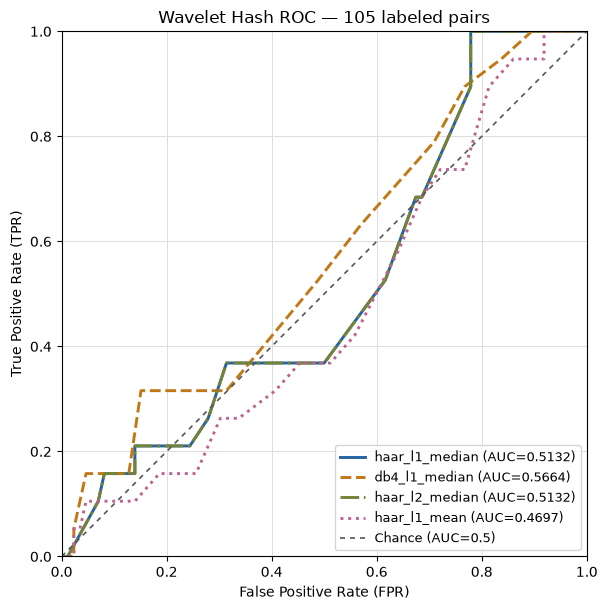

In [6]:
palette = {"haar_l1_median": "#2463A0", "db4_l1_median": "#C17817",
           "haar_l2_median": "#748337", "haar_l1_mean": "#BE6291"}
styles = {"haar_l1_median": "-", "db4_l1_median": "--",
          "haar_l2_median": "-.", "haar_l1_mean": ":"}
if roc_curves:
    fig, ax = plt.subplots(figsize=(8.4, 6.2))
    for config in CONFIGS:
        key = config["config_id"]
        if key not in roc_curves:
            continue
        curve = roc_curves[key]
        ax.plot(curve["fpr"], curve["tpr"], color=palette[key], linestyle=styles[key],
                linewidth=2.1, label=f'{key} (AUC={curve["auc"]:.4f})')
    ax.plot([0,1], [0,1], color="#555555", linestyle=(0,(3,3)), linewidth=1.2, label="Chance (AUC=0.5)")
    ax.set(xlim=(0,1), ylim=(0,1), xlabel="False Positive Rate (FPR)",
           ylabel="True Positive Rate (TPR)", title=f"Wavelet Hash ROC — {len(pairs)} labeled pairs")
    ax.set_aspect("equal", adjustable="box")
    ax.grid(color="#DDDDDD", linewidth=0.7)
    ax.legend(loc="lower right", fontsize=9)
    fig.tight_layout()
    fig.savefig(OUT / "roc_comparison.png", dpi=160, facecolor="white")
    plt.show()
else:
    display(Markdown("**ROC/AUC không xác định:** nguồn chỉ có một lớp nhãn; giữ bảng metrics và AUC=N/A."))

Baseline, threshold=16: 6 FP; 17 FN.


error,config_id,image1,image2,label,notes,distance,bit_length,score
FP,haar_l1_median,data/input/anh_dem.jpg,data/input/da_mat.jpg,0,Khác nhóm nội dung/chủ thể chính.,16,64,-16
FP,haar_l1_median,data/input/cong_trinh.jpg,data/input/rung_cay.jpg,0,Khác nhóm nội dung/chủ thể chính.,16,64,-16
FN,haar_l1_median,data/input/anh_dem.jpg,data/input/cong_trinh.jpg,1,Cùng nhóm cảnh đô thị/đường phố/công trình.,36,64,-36
FN,haar_l1_median,data/input/anh_dem.jpg,data/input/pho_co.jpg,1,Cùng nhóm cảnh đô thị/đường phố/công trình.,32,64,-32


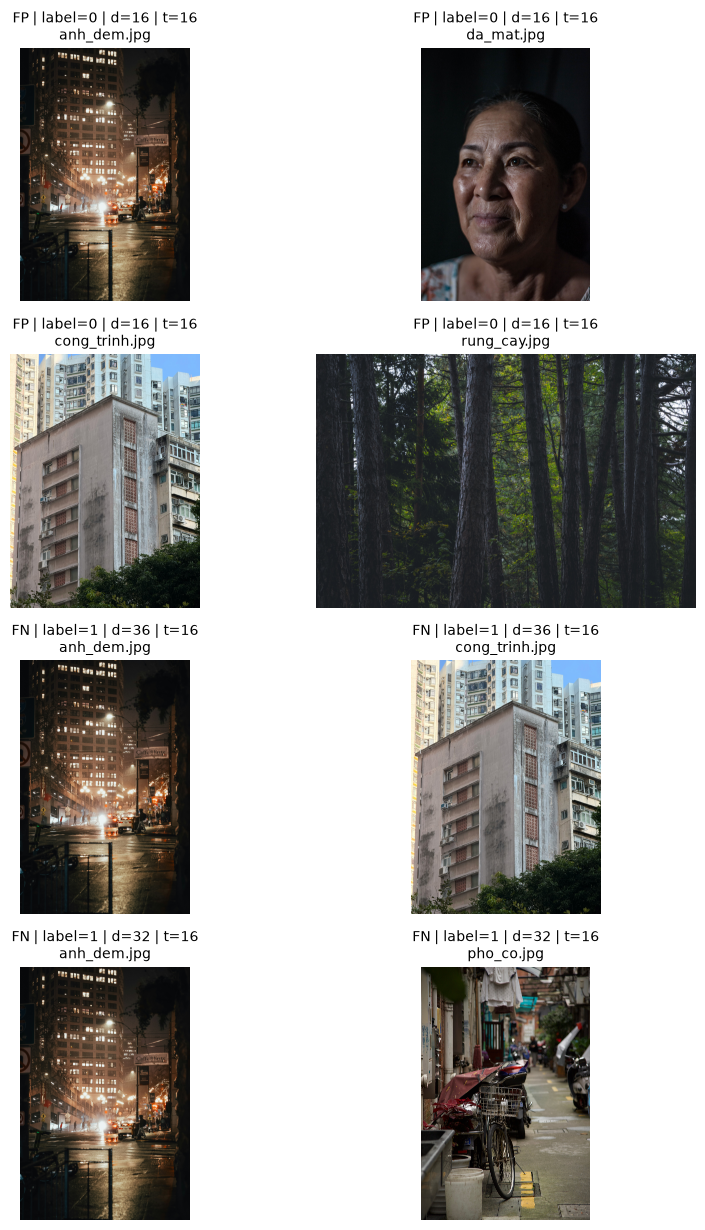

In [7]:
BASELINE, REVIEW_THRESHOLD = "haar_l1_median", 16
baseline = [r for r in pair_scores if r["config_id"] == BASELINE]
false_positives = [r for r in baseline if r["label"] == 0 and r["distance"] <= REVIEW_THRESHOLD]
false_negatives = [r for r in baseline if r["label"] == 1 and r["distance"] > REVIEW_THRESHOLD]
print(f"Baseline, threshold={REVIEW_THRESHOLD}: {len(false_positives)} FP; {len(false_negatives)} FN.")
# Ưu tiên có cả hai loại nếu có, tối đa bốn cặp; thứ tự nguồn ổn định.
selected = false_positives[:2] + false_negatives[:2]
for row in false_positives + false_negatives:
    if len(selected) >= 4:
        break
    if row not in selected:
        selected.append(row)
show_table([dict(error="FP" if r["label"] == 0 else "FN", **r) for r in selected])
if selected:
    fig, axes = plt.subplots(len(selected), 2, figsize=(9, 3.1*len(selected)), squeeze=False)
    for i, row in enumerate(selected):
        kind = "FP" if row["label"] == 0 else "FN"
        for j, key in enumerate(("image1", "image2")):
            image = cv2.imread(str(image_root / row[key]))
            if image is None:
                raise FileNotFoundError(row[key])
            axes[i,j].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
            axes[i,j].set_title(f'{kind} | label={row["label"]} | d={row["distance"]} | t=16\n{Path(row[key]).name}', fontsize=10)
            axes[i,j].axis("off")
    fig.tight_layout()
    plt.show()
else:
    display(Markdown("Không có cặp sai tại ngưỡng đang xem."))

## 6. Nhận xét, giới hạn và bàn giao
Cell sau rút nhận xét trực tiếp từ bảng đã tính; các ảnh FP/FN phía trên giúp đối chiếu hình ảnh với nhãn TV2. Hash biểu diễn cấu trúc/độ sáng ở độ phân giải thấp, còn nhãn cùng nhóm nội dung có thể yêu cầu ngữ nghĩa. Vì vậy có thể xảy ra FP giữa ảnh khác nội dung nhưng giống bố cục và FN giữa ảnh cùng nhóm nhưng khác góc nhìn/chi tiết. Đây là cách diễn giải cần đối chiếu từng cặp, không phải nguyên nhân đã được chứng minh cho mọi lỗi.

In [8]:
n_pos, n_neg = labels.count(1), labels.count(0)
valid_auc = [r for r in summary if not math.isnan(r["auc"])]
if valid_auc:
    best_auc = max(r["auc"] for r in valid_auc)
    leaders = ", ".join(r["config_id"] for r in valid_auc if r["auc"] == best_auc)
    display(Markdown(f"Trên **chính {len(pairs)} cặp này**, AUC cao nhất trong bốn cấu hình là **{best_auc:.4f}** ({leaders}). Đây là so sánh mô tả, chưa chứng minh cấu hình tốt nhất cho bộ ảnh khác."))
base_metric = next(r for r in metrics if r["config_id"] == BASELINE and r["threshold"] == REVIEW_THRESHOLD)
display(Markdown(f"Nguồn có **{n_pos} dương / {n_neg} âm**. Tại baseline/ngưỡng 16: TP={base_metric['TP']}, FP={base_metric['FP']}, TN={base_metric['TN']}, FN={base_metric['FN']}. Cần đọc Recall/Specificity/Precision cùng Accuracy do mất cân bằng lớp; mẫu số 0 hiển thị N/A."))

Trên **chính 105 cặp này**, AUC cao nhất trong bốn cấu hình là **0.5664** (db4_l1_median). Đây là so sánh mô tả, chưa chứng minh cấu hình tốt nhất cho bộ ảnh khác.

Nguồn có **19 dương / 86 âm**. Tại baseline/ngưỡng 16: TP=2, FP=6, TN=80, FN=17. Cần đọc Recall/Specificity/Precision cùng Accuracy do mất cân bằng lớp; mẫu số 0 hiển thị N/A.

**Đọc kết quả lần chạy lưu kèm:** baseline/ngưỡng 16 có Accuracy **0.7810**, nhưng Recall chỉ **0.1053** (2/19 cặp tương tự) và Precision **0.2500**. Vì vậy Accuracy riêng lẻ không phản ánh khả năng nhận ra cặp tương tự. Hai cấu hình Haar median L1/L2 cho cùng khoảng cách trên bộ dữ liệu này; không cần mở rộng thử nghiệm chỉ để tìm khác biệt. AUC dưới 0.5 ở Haar mean được báo đúng chiều score đã chọn, không tự đảo score để làm chỉ số cao hơn.

**Giới hạn:** Bộ ảnh/cặp nhỏ, một ảnh xuất hiện trong nhiều cặp nên các dòng không độc lập. Không chia ngẫu nhiên cặp thành train/test để tránh cùng ảnh xuất hiện ở cả hai phía. Chưa có bộ ảnh độc lập, khoảng tin cậy hoặc kiểm định để suy rộng; không dùng bảng này để tuyên bố ngưỡng tối ưu. Kết quả phụ thuộc nguồn TV2, cách tiền xử lý và tham số TV4 đã ghi rõ.

**Bàn giao TV1/TV5:** Ba CSV và `roc_comparison.png` nằm tại `lab_4/results/tv6_evaluation/`. Dùng `config_id` để nối bảng; mỗi cặp/cấu hình có đúng một distance/score. Khi ghép module TV5 chính thức, giữ quy tắc `distance <= threshold`, hash 64 bit và cùng tham số; so lại distance trước khi đánh giá. Kết quả hiện tại xác nhận luồng TV6 với helper TV4, chưa xác nhận toàn bộ pipeline nhóm đã tích hợp.

**Chạy lại:** Dùng môi trường dự án có NumPy, OpenCV, PyWavelets, Matplotlib và Jupyter; mở từ root repo hoặc `lab_4/notebook`, Restart Kernel & Run All. Notebook tự đọc nguồn local, tính lại và ghi đúng thư mục TV6; không cần file tạm trong `.qa`.